# Load Data

In [1]:
!pip install gdown --q

In [2]:
!pip install datasets --q

In [3]:
from datasets import load_dataset, Dataset, DatasetDict, Features, Image as HFImage, ClassLabel
from huggingface_hub import hf_hub_download
import zipfile
import os
import tempfile

def load_liveness_dataset():
    """Load liveness dataset. Uses fallback (download zip, build from filenames) if HF loader fails due to invalid labels."""
    try:
        return load_dataset("Bahareh0281/liveness_images")
    except Exception as e:
        if "Invalid string class label" not in str(e) and "DatasetGenerationError" not in type(e).__name__:
            raise
        print("Dataset loader failed (invalid label in repo). Loading from zip with filename-based labels (_real=1, _fake=0)...")
    data_dir = tempfile.mkdtemp(prefix="liveness_")
    zip_path = hf_hub_download(repo_id="Bahareh0281/liveness_images", filename="liveness_images.zip", repo_type="dataset")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(data_dir)
    paths, labels = [], []
    for root, _, files in os.walk(data_dir):
        for f in files:
            if not f.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            path = os.path.join(root, f)
            rel_parts = os.path.relpath(root, data_dir).split(os.sep)
            rel_parts_lower = [p.lower() for p in rel_parts]
            f_lower = f.lower()
            label = None
            if "fake" in rel_parts_lower or "fake" in f_lower:
                label = 0
            elif "real" in rel_parts_lower or "real" in f_lower:
                label = 1
            elif any(p == "0" for p in rel_parts_lower):
                label = 0
            elif any(p == "1" for p in rel_parts_lower):
                label = 1
            if label is not None:
                paths.append(path)
                labels.append(label)
    if not paths:
        seen = []
        for root, _, files in os.walk(data_dir):
            imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
            if imgs:
                rel = os.path.relpath(root, data_dir)
                seen.append((rel, imgs[:3]))
            if len(seen) >= 5:
                break
        msg = "No images with 'real'/'fake' in path or filename found in zip."
        if seen:
            msg += " Sample paths: " + str(seen[:5])
        raise RuntimeError(msg)
    ds = Dataset.from_dict({"image": paths, "label": labels})
    ds = ds.cast_column("image", HFImage()).cast_column("label", ClassLabel(num_classes=2, names=["fake", "real"]))
    return DatasetDict({"train": ds})

dataset = load_liveness_dataset()

Generating train split:   0%|          | 0/6427 [00:00<?, ? examples/s]

Dataset loader failed (invalid label in repo). Loading from zip with filename-based labels (_real=1, _fake=0)...


Casting the dataset:   0%|          | 0/6427 [00:00<?, ? examples/s]

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os

In [5]:
# def load_image_paths(directory):
#     image_paths = []
#     for filename in os.listdir(directory):
#         if filename.endswith(".jpg") or filename.endswith(".png"):
#             image_paths.append(os.path.join(directory, filename))
#     return image_paths

# image_paths = load_image_paths('/content/train_img/train_img/color')

In [6]:
# output_dir = '/content/train_img/train_img/color'

## Labels Extraction

In [7]:
dataset['train'][0]['label']

0

## Load [Our Videos](https://drive.google.com/file/d/1a5R5h05hCyw9PzIBhSjy2jLL3dSFy2xA/view?usp=sharing)

In [8]:
import gdown

file_id = '1a5R5h05hCyw9PzIBhSjy2jLL3dSFy2xA'
import os
data_dir = os.path.join('.', 'data')
os.makedirs(data_dir, exist_ok=True)
destination = os.path.join(data_dir, 'dataset.zip')  # Windows-compatible path
gdown.download(f'https://drive.google.com/uc?id={file_id}', destination, quiet=False)

import zipfile

with zipfile.ZipFile(destination, 'r') as zip_ref:
    extract_dir = os.path.join(data_dir, 'dataset')
    os.makedirs(extract_dir, exist_ok=True)
    zip_ref.extractall(extract_dir)


Downloading...
From (original): https://drive.google.com/uc?id=1a5R5h05hCyw9PzIBhSjy2jLL3dSFy2xA
From (redirected): https://drive.google.com/uc?id=1a5R5h05hCyw9PzIBhSjy2jLL3dSFy2xA&confirm=t&uuid=6fab9180-f476-4e33-8de0-4f4f18e22956
To: D:\Projects\Face-Modle\Video-Based-Face-Liveness-Detection\notebooks\data\dataset.zip
100%|██████████████████████████████████████████| 377M/377M [00:16<00:00, 22.9MB/s]


### Random Frame Extraction

In [9]:
import os
import random
import cv2
from PIL import Image

In [10]:
def extract_frames(video_path, save_path, label, test, filename):
    # Open the video file
    video = cv2.VideoCapture(video_path)
    frame_count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

    # Select one random frame
    random_frame = random.randint(0, frame_count - 1)

    # Set the position of the video to the selected frame
    video.set(cv2.CAP_PROP_POS_FRAMES, random_frame)
    success, frame = video.read()

    # If the frame was successfully read, save it
    if success:
        frame_path = os.path.join(save_path, f"{label}_{filename.split('.')[0]}.jpg")
        cv2.imwrite(frame_path, frame)

        # Convert the frame to a PIL image
        pil_image = Image.open(frame_path)

        # Save the image and label to the dictionary
        test.append({'image': pil_image, 'label': label})

    # Release the video file
    video.release()

In [11]:
import cv2

import os
data_dir = os.path.join('.', 'data')
fake_test_videos_path = os.path.join(data_dir, 'dataset', 'fake', 'test')
real_test_videos_path = os.path.join(data_dir, 'dataset', 'real', 'test')

save_frames_path = os.path.join(data_dir, 'extracted_frames', 'test')
# Create the directory if it doesn't exist
if not os.path.exists(save_frames_path):
    os.makedirs(save_frames_path)

# Create a list to hold the dictionary entries
test = []

# Iterate over fake videos and extract frames
for fake_video_file in os.listdir(fake_test_videos_path):
    fake_video_path = os.path.join(fake_test_videos_path, fake_video_file)
    extract_frames(fake_video_path, save_frames_path, 0, test, fake_video_file)

# Iterate over real videos and extract frames
for real_video_file in os.listdir(real_test_videos_path):
    real_video_path = os.path.join(real_test_videos_path, real_video_file)
    extract_frames(real_video_path, save_frames_path, 1, test, real_video_file)

In [12]:
print(test[0]['image'])
print(test[0]['label'])

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1080x2400 at 0x1FBDA12EC50>
0


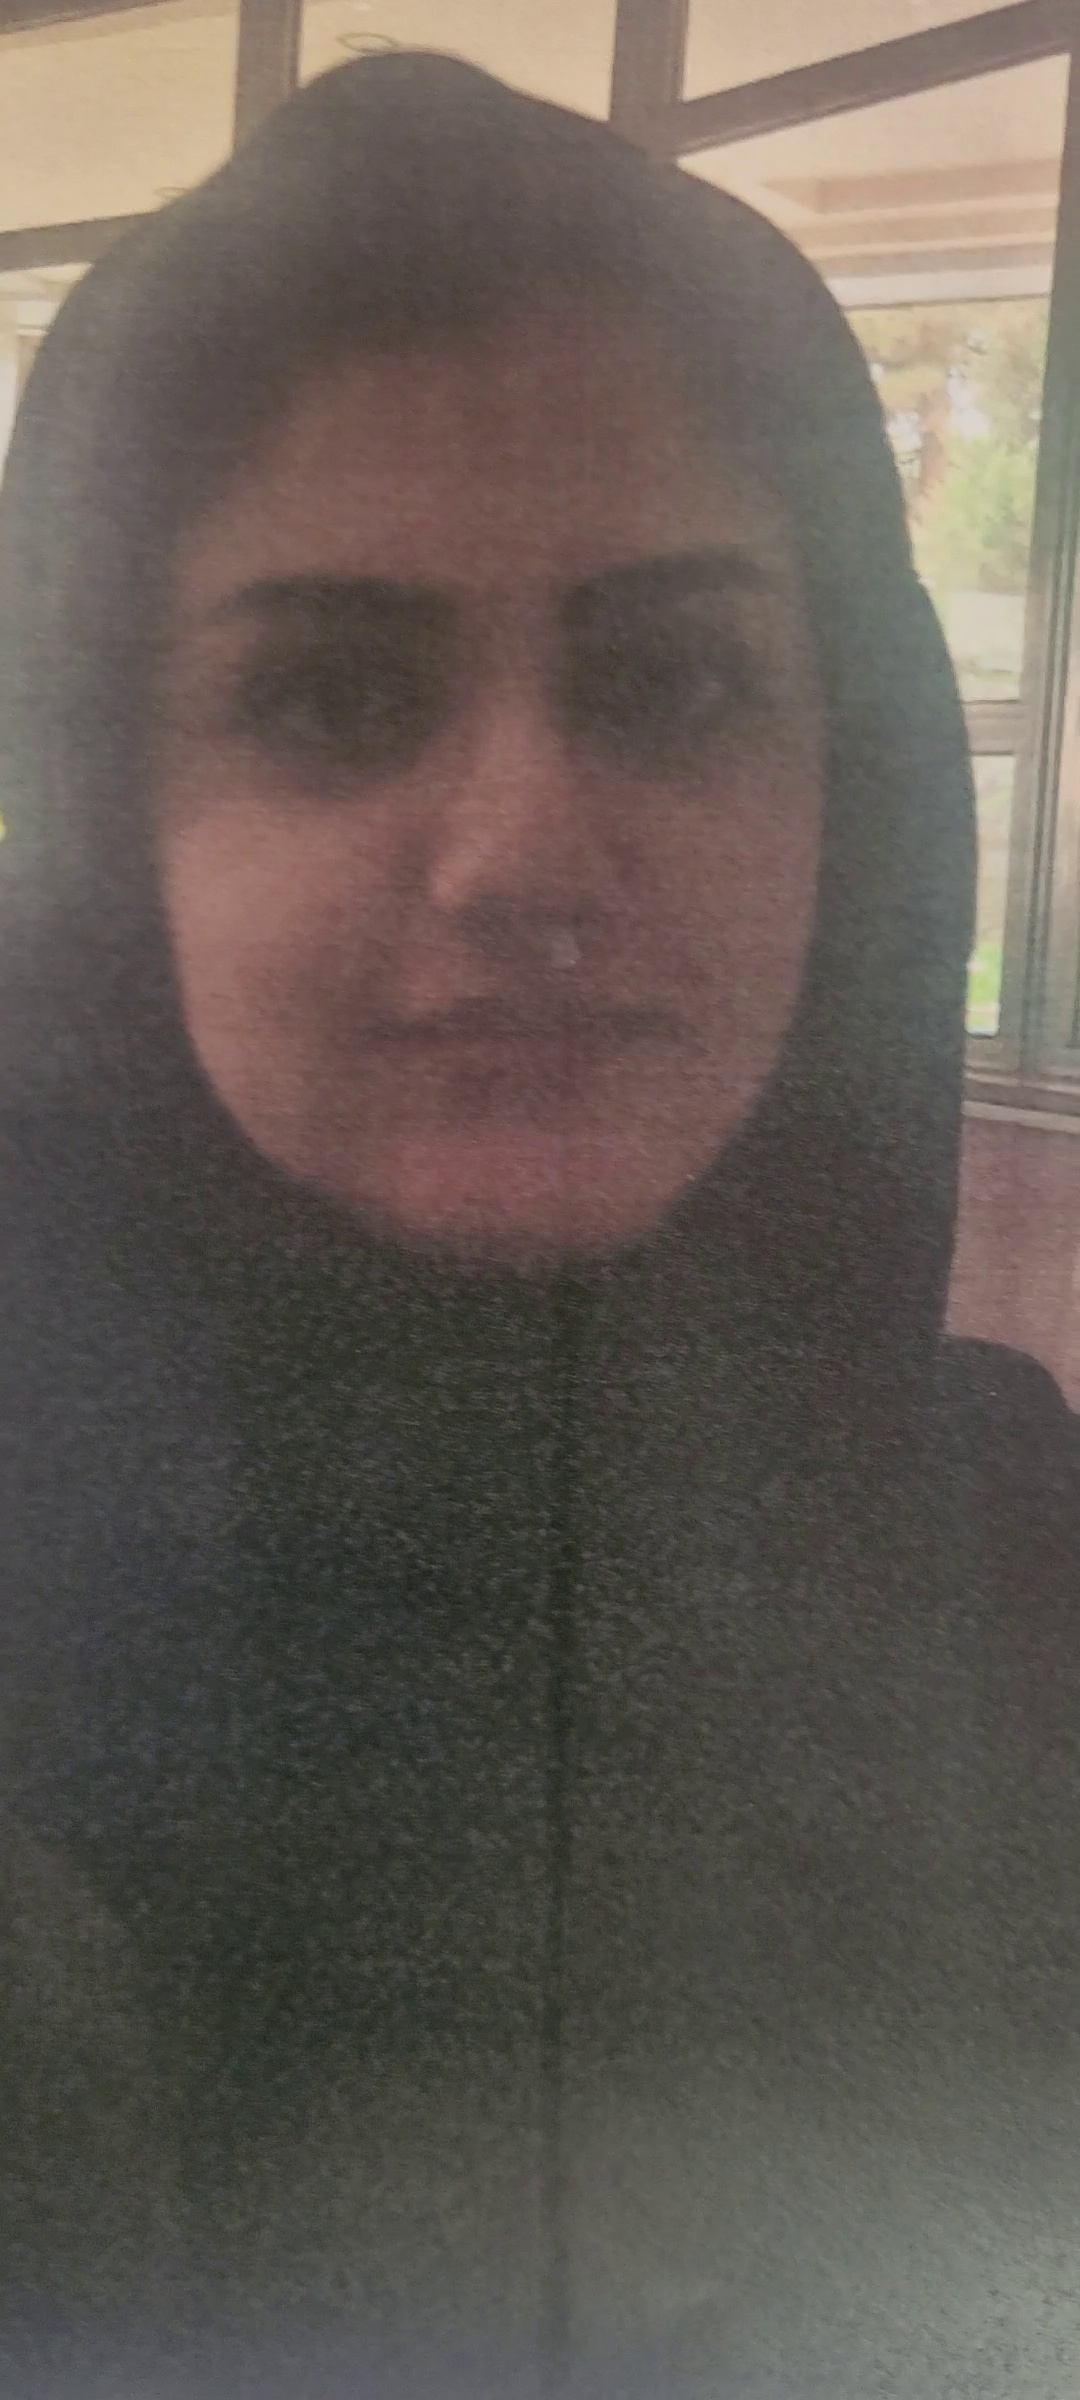

In [13]:
test[0]['image']

# ResNet50

In [14]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
import cv2

## Preparing Images

In [15]:
import numpy as np
from PIL import Image

# Assuming images is a list of PIL Image objects
images_np = []
labels = []
for i in range(3000):
    #example = dataset['train'][i]
    image = np.array(dataset['train'][i]['image'])
    rgb_img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    img_np = np.array(rgb_img)
    images_np.append(cv2.resize(img_np, (224, 224)))
    labels.append(dataset['train'][i]['label'])
# Now images_np should contain numpy arrays representing each image
print(images_np[0].shape)  # Check the shape of the first image numpy array
print(labels[0])

(224, 224, 3)
0


In [16]:
len(images_np)

3000

## Training the model

In [17]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [18]:
# Convert labels to one-hot encoding
labels_onehot = to_categorical(np.array(labels), num_classes=2)

# Convert images_np list to numpy array
images_np_np = np.array(images_np)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(images_np_np, labels_onehot, test_size=0.2, random_state=42)

In [19]:
# Print shapes for verification
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (2400, 224, 224, 3)
y_train shape: (2400, 2)
X_test shape: (600, 224, 224, 3)
y_test shape: (600, 2)


In [20]:
# Load ResNet50 model pre-trained on ImageNet
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add custom layers on top of ResNet50
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)

In [21]:
# Define the model
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze the layers of ResNet50
for layer in base_model.layers:
    layer.trainable = False

In [22]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)         ┃ Output Shape       ┃    Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ input_layer          │ (None, 224, 224,   │          0 │ -                  │
│ (InputLayer)         │ 3)                 │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv1_pad            │ (None, 230, 230,   │          0 │ input_layer[0][0]  │
│ (ZeroPadding2D)      │ 3)                 │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv1_conv (Conv2D)  │ (None, 112, 112,   │      9,472 │ conv1_pad[0][0]    │
│                      │ 64)                │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv1_bn             │ (None, 112, 112,   │        256 │ conv1_conv[0][0]   │
│ (BatchNormalization) │ 64)                │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv1_relu           │ (None, 112, 112,   │          0 │ conv1_bn[0][0]     │
│ (Activation)         │ 64)                │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ pool1_pad            │ (None, 114, 114,   │          0 │ conv1_relu[0][0]   │
│ (ZeroPadding2D)      │ 64)                │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ pool1_pool           │ (None, 56, 56, 64) │          0 │ pool1_pad[0][0]    │
│ (MaxPooling2D)       │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_1_conv  │ (None, 56, 56, 64) │      4,160 │ pool1_pool[0][0]   │
│ (Conv2D)             │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_1_bn    │ (None, 56, 56, 64) │        256 │ conv2_block1_1_co… │
│ (BatchNormalization) │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_1_relu  │ (None, 56, 56, 64) │          0 │ conv2_block1_1_bn… │
│ (Activation)         │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_2_conv  │ (None, 56, 56, 64) │     36,928 │ conv2_block1_1_re… │
│ (Conv2D)             │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_2_bn    │ (None, 56, 56, 64) │        256 │ conv2_block1_2_co… │
│ (BatchNormalization) │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_2_relu  │ (None, 56, 56, 64) │          0 │ conv2_block1_2_bn… │
│ (Activation)         │                    │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_0_conv  │ (None, 56, 56,     │     16,640 │ pool1_pool[0][0]   │
│ (Conv2D)             │ 256)               │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_3_conv  │ (None, 56, 56,     │     16,640 │ conv2_block1_2_re… │
│ (Conv2D)             │ 256)               │            │                    │
├──────────────────────┼────────────────────┼────────────┼────────────────────┤
│ conv2_block1_0_bn    │ (None, 56, 56,     │      1,024 │ conv2_block1_0_co… │
│ (BatchNormalization) │ 256)               │            │                    │


 Total params: 25,687,938 (97.99 MB)

 Trainable params: 2,100,226 (8.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# Train the model
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/10
65/75 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.8166 - loss: 0.7241

In [ ]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy * 100}%")

In [ ]:
# Save the model
model.save('anti_spoofing_model_resnet50_deep_fullface.h5')

## Testing the model

In [ ]:
import os
import os
data_dir = os.path.join('.', 'data')
# Path to your test images
test_images_dir = os.path.join(data_dir, 'extracted_frames', 'test')

In [ ]:
# Function to resize images in a directory
def resize_images(directory, target_size=(224, 224)):
    resized_images = []
    test_image_paths = []
    test_image_labels = []

    # Iterate over each image in the directory
    for filename in os.listdir(directory):
        if filename.endswith(".jpg") or filename.endswith(".png"):
            label = filename.split('.')[0].split('_')[0]
            image_path = os.path.join(directory, filename)
            image = cv2.imread(image_path)
            resized_image = cv2.resize(image, target_size)

            # Append resized image, image path, and label
            resized_images.append(resized_image)
            test_image_paths.append(image_path)
            test_image_labels.append(int(label))  # Convert label to int

    # Convert lists to numpy arrays
    resized_images = np.array(resized_images)
    test_image_labels = np.array(test_image_labels)

    return resized_images, test_image_paths, test_image_labels

In [ ]:
# Resize images in test directory
resized_images, test_image_paths, test_image_labels = resize_images(test_images_dir)

# Check the shape of resized images
print("Resized images shape:", resized_images.shape)

In [ ]:
# Convert labels to one-hot encoding
test_image_labels_onehot = to_categorical(test_image_labels, num_classes=2)

In [ ]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(resized_images, test_image_labels_onehot)

### Wrong Answers

In [ ]:
import os

# Directory containing the images
image_directory = test_images_dir

# Get the predicted labels for the test images
predictions = model.predict(resized_images)
predicted_labels = np.argmax(predictions, axis=1)

print("Total test images: ", len(predicted_labels))
# Get the true labels
true_labels = np.argmax(test_image_labels_onehot, axis=1)

# Find the names of incorrectly classified images
incorrect_image_names = []
for index, (predicted_label, true_label) in enumerate(zip(predicted_labels, true_labels)):
    if predicted_label != true_label:
        image_name = os.listdir(image_directory)[index]
        incorrect_image_names.append(image_name)
print("Wrong: ", len(incorrect_image_names))
# Display the names of incorrectly classified images
for image_name in incorrect_image_names:
    print(f"Incorrectly classified image: {image_name}")

### Predictions

In [ ]:
import csv

In [ ]:
predictions = model.predict(resized_images)
predicted_scores = predictions[:, 1]
# Normalize scores between 0 and 1
predicted_scores_normalized = (predicted_scores - np.min(predicted_scores)) / (np.max(predicted_scores) - np.min(predicted_scores))

# Save predictions to a CSV file
output_file = 'predictions.csv'
with open(output_file, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'liveness_score'])  # Header
    for i, filename in enumerate(test_image_paths):
        correct_filename = filename.split('/')[4].split('.')[0]
        correct_filename += ".mp4"
        writer.writerow([correct_filename, predicted_scores_normalized[i]])

print(f"Predictions saved to {output_file}")

## Testing the Model with Cropped Images (Using MTCNN)

In [ ]:
!pip install mtcnn --q

In [ ]:
from mtcnn import MTCNN

In [ ]:
def load_image_paths(directory):
    image_paths = []
    for filename in os.listdir(directory):
        if filename.endswith(".jpg") or filename.endswith(".png"):
            image_paths.append(os.path.join(directory, filename))
    return image_paths

In [ ]:
def detect_and_crop_faces(image_path, detector):
    image = Image.open(image_path)
    image_np = np.asarray(image)
    result = detector.detect_faces(image_np)
    if result:
        for person in result:
            bounding_box = person['box']
            keypoints = person['keypoints']

            # Crop the detected face
            x, y, width, height = bounding_box
            cropped_face = image_np[y:y+height, x:x+width]

            # Convert the cropped face back to an image
            cropped_face_image = Image.fromarray(cropped_face)

            return cropped_face_image
    return None

In [ ]:
# Initialize the MTCNN face detector
detector = MTCNN()

In [ ]:
import os
data_dir = os.path.join('.', 'data')
# Directory containing the original images
test_image_paths = load_image_paths(test_images_dir)

# Directory to save cropped face images
output_dir = os.path.join(data_dir, 'cropped_faces')
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Process each image and save the cropped face with the original filename
for image_path in test_image_paths:
    cropped_face = detect_and_crop_faces(image_path, detector)
    # print("Image path is:", test_image_paths)
    if cropped_face:
        # Extract the original filename
        original_filename = os.path.basename(image_path)
        # Save the cropped face image with the original filename
        cropped_face.save(os.path.join(output_dir, original_filename))

In [ ]:
# Resize images in test directory
cropped_resized_images, cropped_test_image_paths, cropped_test_image_labels = resize_images(output_dir)

# Check the shape of resized images
print("Resized images shape:", cropped_resized_images.shape)

In [ ]:
# Convert labels to one-hot encoding
cropped_test_image_labels_onehot = to_categorical(cropped_test_image_labels, num_classes=2)

In [ ]:
# Evaluate the model
cropped_test_loss, cropped_test_accuracy = model.evaluate(cropped_resized_images, cropped_test_image_labels_onehot)

In [ ]:
# Predictions
cropped_predictions = model.predict(cropped_resized_images)
cropped_predicted_scores = cropped_predictions[:, 1]  # Assuming class 1 corresponds to index 1 in predictions

# Normalize scores between 0 and 1
cropped_predicted_scores_normalized = (cropped_predicted_scores - np.min(cropped_predicted_scores)) / (np.max(cropped_predicted_scores) - np.min(cropped_predicted_scores))

In [ ]:
# Save predictions to a CSV file
output_file = 'predictions.csv'
with open(output_file, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'liveness_score', 'liveness_score_crop'])  # Header
    for i, filename in enumerate(test_image_paths):
        writer.writerow([filename, predicted_scores_normalized[i], cropped_predicted_scores_normalized[i]])

print(f"Predictions saved to {output_file}")

# Testing Google model

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import ViTImageProcessor, ViTForImageClassification
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import numpy as np

In [ ]:
# Step 1: Load pretrained model and processor
processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224')
model = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224')

# Freeze the base model
for param in model.parameters():
    param.requires_grad = False

# Modify the classifier head
model.classifier = nn.Linear(model.config.hidden_size, 2)
nn.init.xavier_uniform_(model.classifier.weight)

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

In [ ]:
# Step 2: Convert data to PyTorch tensors and permute dimensions
# Normalize the image data
X_train_pt = torch.tensor(X_train / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
X_test_pt = torch.tensor(X_test / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
y_train_pt = torch.tensor(y_train, dtype=torch.long).to(device)
y_test_pt = torch.tensor(y_test, dtype=torch.long).to(device)


In [ ]:
# Step 3: Define optimizer and criterion for the classifier head
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-5)  # Only optimize classifier parameters
criterion = nn.CrossEntropyLoss()

In [ ]:
# Step 4: Training loop
model.train()
epochs = 15
batch_size = 32

for epoch in range(epochs):
    total_loss = 0
    for i in range(0, len(X_train), batch_size):
        batch_inputs = X_train_pt[i:i+batch_size]
        batch_labels = y_train_pt[i:i+batch_size]

        optimizer.zero_grad()

        outputs = model(pixel_values=batch_inputs)
        loss = criterion(outputs.logits, torch.argmax(batch_labels, dim=1))

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss}")


In [ ]:
# Step 5: Unfreeze all layers for fine-tuning
for param in model.parameters():
    param.requires_grad = True

# Use a smaller learning rate for fine-tuning the entire model
optimizer = optim.Adam(model.parameters(), lr=1e-6)
criterion = nn.BCEWithLogitsLoss()  # Use this if model outputs logits

# Ensure your targets are float
y_train_pt = torch.tensor(y_train_pt, dtype=torch.float)
y_test_pt = torch.tensor(y_test_pt, dtype=torch.float)

# Training loop remains similar
for epoch in range(15):
    total_loss = 0
    for i in range(0, len(X_train), batch_size):
        batch_inputs = X_train_pt[i:i+batch_size]
        batch_labels = y_train_pt[i:i+batch_size]

        optimizer.zero_grad()

        outputs = model(pixel_values=batch_inputs)
        loss = criterion(outputs.logits, batch_labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Fine-tuning Epoch {epoch+1}/{15}, Train Loss: {total_loss:.4f}")


In [ ]:
# Normalize the image data
X_train_pt = torch.tensor(X_train / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
X_test_pt = torch.tensor(X_test / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
y_train_pt = torch.tensor(y_train, dtype=torch.long).to(device)
y_test_pt = torch.tensor(y_test, dtype=torch.long).to(device)

In [ ]:
import torch

# Ensure your model and tensors are on the correct device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Assuming X_test_pt and y_test_pt are preprocessed and available on the correct device
X_test_pt = X_test_pt.to(device)
y_test_pt = y_test_pt.to(device)

# Set the model to evaluation mode
model.eval()
correct = 0
total = 0
batch_size = 32  # Set your batch size

with torch.no_grad():
    for i in range(0, len(X_test_pt), batch_size):
        batch_inputs = X_test_pt[i:i+batch_size]
        batch_labels = y_test_pt[i:i+batch_size]

        # Ensure the inputs are on the correct device
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(pixel_values=batch_inputs)
        _, predicted = torch.max(outputs.logits, 1)

        total += batch_labels.size(0)
        correct += (predicted == torch.argmax(batch_labels, dim=1)).sum().item()

accuracy = 100 * correct / total
print(f"Final Accuracy on test set: {accuracy:.2f}%")


In [ ]:
# Set the model to evaluation mode
model.eval()
correct = 0
total = 0
total_loss = 0.0
batch_size = 32  # Set your batch size

criterion = nn.CrossEntropyLoss()  # Use CrossEntropyLoss for accuracy calculation

with torch.no_grad():
    for i in range(0, len(X_test_pt), batch_size):
        batch_inputs = X_test_pt[i:i+batch_size]
        batch_labels = y_test_pt[i:i+batch_size]

        # Ensure the inputs are on the correct device
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(pixel_values=batch_inputs)
        loss = criterion(outputs.logits, torch.argmax(batch_labels, dim=1))

        total_loss += loss.item()

        _, predicted = torch.max(outputs.logits, 1)
        total += batch_labels.size(0)
        correct += (predicted == torch.argmax(batch_labels, dim=1)).sum().item()

average_loss = total_loss / len(X_test_pt)
accuracy = 100 * correct / total

print(f"Final Accuracy on test set: {accuracy:.2f}%")
print(f"Final Loss on test set: {average_loss:.4f}")


In [ ]:
import torch
import csv
import numpy as np

# Set the model to evaluation mode
model.eval()

# Ensure your data is on the correct device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
X_test_pt = torch.tensor(X_test / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)

predictions = []

with torch.no_grad():
    for i in range(0, len(X_test_pt), batch_size):
        batch_inputs = X_test_pt[i:i+batch_size]
        batch_inputs = batch_inputs.to(device)
        outputs = model(pixel_values=batch_inputs)
        scores = outputs.logits.softmax(dim=1)[:, 1].cpu().numpy()  # Assuming binary classification
        predictions.extend(scores)

# Normalize scores between 0 and 1
predicted_scores_normalized = (np.array(predictions) - np.min(predictions)) / (np.max(predictions) - np.min(predictions))

In [ ]:
# Save predictions to a CSV file
output_file = 'Google_predictions.csv'
with open(output_file, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'liveness_score'])  # Header
    for i, filename in enumerate(test_image_paths):
        correct_filename = filename.split('/')[4].split('.')[0]
        correct_filename += ".mp4"
        print(correct_filename)
        writer.writerow([correct_filename, predicted_scores_normalized[i]])

print(f"Predictions saved to {output_file}")

### Testing Cropped Data

In [ ]:
# Normalize the image data and convert to PyTorch tensors
cropped_test_images_pt = torch.tensor(cropped_resized_images / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
cropped_test_labels_pt = torch.tensor(cropped_test_image_labels_onehot, dtype=torch.long).to(device)

# Set the model to evaluation mode
model.eval()

correct = 0
total = 0
total_loss = 0.0
batch_size = 32  # Set your batch size

criterion = nn.CrossEntropyLoss()  # Assuming you are using CrossEntropyLoss for multi-class classification

with torch.no_grad():
    for i in range(0, len(cropped_test_images_pt), batch_size):
        batch_inputs = cropped_test_images_pt[i:i+batch_size]
        batch_labels = cropped_test_labels_pt[i:i+batch_size]

        # Ensure the inputs are on the correct device
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(pixel_values=batch_inputs)
        loss = criterion(outputs.logits, torch.argmax(batch_labels, dim=1))

        total_loss += loss.item()

        _, predicted = torch.max(outputs.logits, 1)
        total += batch_labels.size(0)
        correct += (predicted == torch.argmax(batch_labels, dim=1)).sum().item()

average_loss = total_loss / len(cropped_test_images_pt)
accuracy = 100 * correct / total

print(f"Final Accuracy on test set: {accuracy:.2f}%")
print(f"Final Loss on test set: {average_loss:.4f}")

In [ ]:
# Normalize the image data and convert to PyTorch tensors
cropped_test_images_pt = torch.tensor(cropped_resized_images / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)

# Set the model to evaluation mode
model.eval()

cropped_predictions = []

with torch.no_grad():
    for i in range(0, len(cropped_test_images_pt), batch_size):
        batch_inputs = cropped_test_images_pt[i:i+batch_size]
        batch_inputs = batch_inputs.to(device)

        outputs = model(pixel_values=batch_inputs)
        scores = outputs.logits.softmax(dim=1)[:, 1].cpu().numpy()  # Assuming binary classification
        cropped_predictions.extend(scores)

# Convert predictions list to numpy array
cropped_predictions = np.array(cropped_predictions)

# Normalize scores between 0 and 1
cropped_predicted_scores_normalized = (cropped_predictions - np.min(cropped_predictions)) / (np.max(cropped_predictions) - np.min(cropped_predictions))

In [ ]:
# Ensure your predictions are numpy arrays for indexing
predicted_scores_normalized = np.array(predicted_scores_normalized)
cropped_predicted_scores_normalized = np.array(cropped_predicted_scores_normalized)

output_file = 'predictions.csv'
with open(output_file, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'liveness_score', 'liveness_score_crop'])  # Header
    for i, filename in enumerate(test_image_paths):
        writer.writerow([filename, predicted_scores_normalized[i], cropped_predicted_scores_normalized[i]])

print(f"Predictions saved to {output_file}")